# ESG Sentiment Classification with a Linear SVM

Classifies short ESG statements about companies and products as **Positive** or **Negative**.

- **Data:** `data/ESG_Sentiment.csv`, 910 labelled sentences (471 positive, 439 negative)
- **Model:** TF-IDF features (English stop words removed, top 5,000 terms) + LinearSVC
- **Split:** 75% train (682) / 25% test (228), stratified, `random_state=42`
- **Result:** 86.84% test accuracy, F1 0.87 for both classes

In [1]:
import warnings
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

warnings.filterwarnings('ignore')
DATA_PATH = '../data/ESG_Sentiment.csv'
CHART_DIR = '../charts'

## 1. Load and prepare the data

In [2]:
df = pd.read_csv(DATA_PATH)
df['Sentiment_Label'] = df['Sentiment'].map({'Positive': 1, 'Negative': 0})
df = df.dropna(subset=['Sentiment_Label'])

print(f"{len(df)} sentences")
print(df['Sentiment'].value_counts())
df[['Product Name', 'Sentence', 'Sentiment']].head()

910 sentences
Sentiment
Positive    471
Negative    439
Name: count, dtype: int64


,Product Name,Sentence,Sentiment
0,Non-renewable Cars,The Non-renewable Cars is widely recognized fo...,Negative
1,Toxic Household,The Toxic Household is widely recognized for i...,Negative
2,Petroleum-based Cars,The Petroleum-based Cars is widely recognized ...,Negative
3,Polluting Household,The Polluting Household is widely recognized f...,Negative
4,Fossil fuel Cars,The Fossil fuel Cars is widely recognized for ...,Negative


## 2. Split, train and evaluate

In [3]:
X, y = df['Sentence'], df['Sentiment_Label']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print(f"Train: {len(X_train)} | Test: {len(X_test)}")

pipeline_svm = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words='english', max_features=5000)),
    ('model', LinearSVC(random_state=42)),
])
pipeline_svm.fit(X_train, y_train)

y_pred_svm = pipeline_svm.predict(X_test)
print(f"Test accuracy: {accuracy_score(y_test, y_pred_svm) * 100:.2f}%\n")
print(classification_report(y_test, y_pred_svm, target_names=['Negative', 'Positive'], digits=3))

Train: 682 | Test: 228
Test accuracy: 86.84%

              precision    recall  f1-score   support

    Negative      0.851     0.882     0.866       110
    Positive      0.886     0.856     0.871       118

    accuracy                          0.868       228
   macro avg      0.868     0.869     0.868       228
weighted avg      0.869     0.868     0.868       228



## 3. Confusion matrix

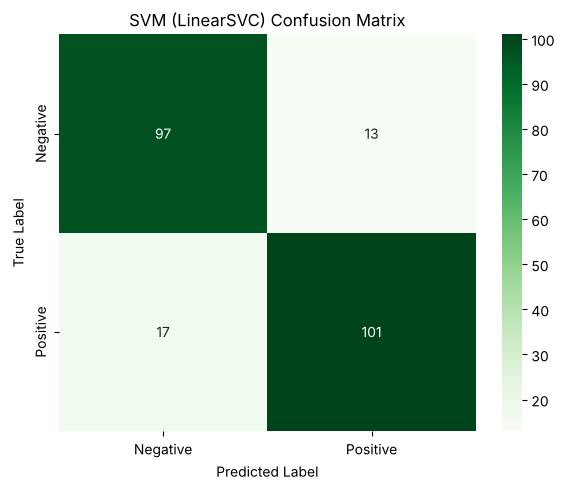

Misclassified: 30 of 228 (false positives: 13, false negatives: 17)


In [4]:
cm = confusion_matrix(y_test, y_pred_svm)
labels = ['Negative', 'Positive']
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=labels, yticklabels=labels)
plt.title('SVM (LinearSVC) Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.savefig(f'{CHART_DIR}/svm_confusion_matrix.png', dpi=150)
plt.show()
print(f"Misclassified: {cm[0,1] + cm[1,0]} of {cm.sum()} (false positives: {cm[0,1]}, false negatives: {cm[1,0]})")

## 4. Which words drive the predictions

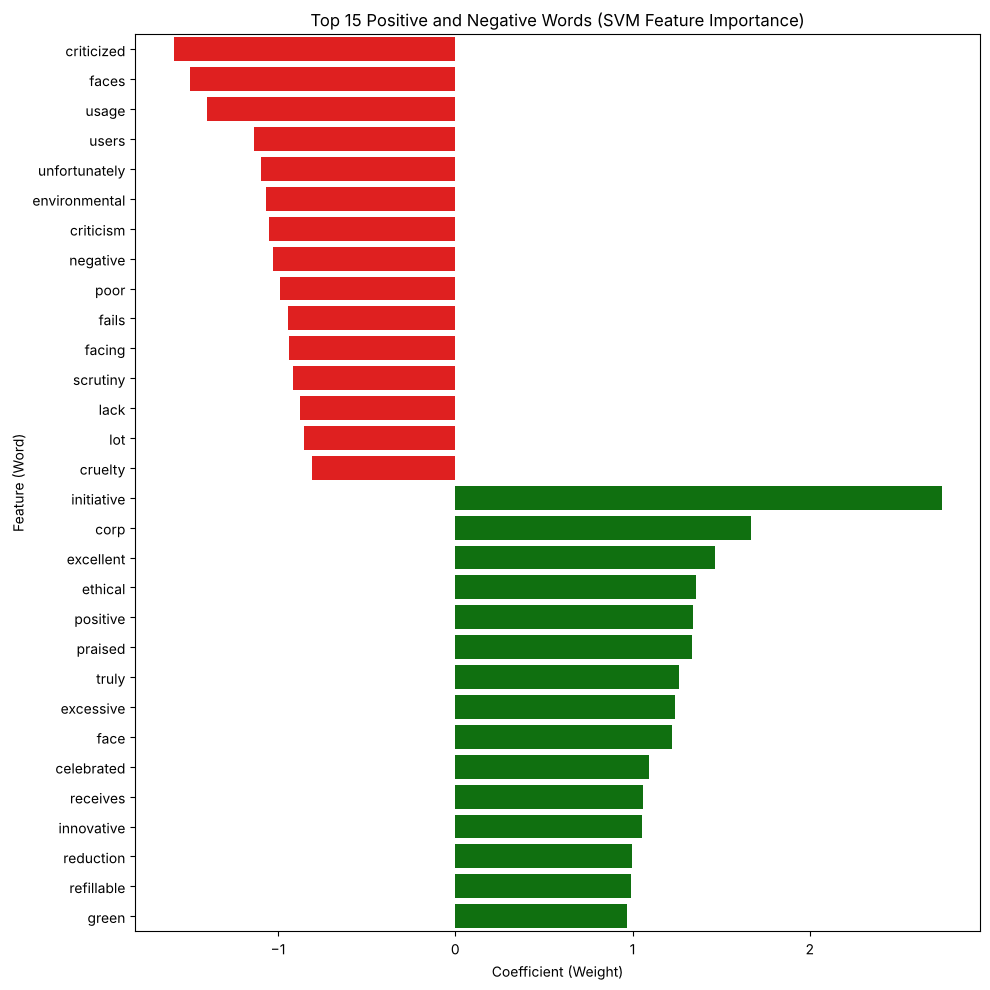

In [5]:
names = pipeline_svm.named_steps['tfidf'].get_feature_names_out()
coefs = pipeline_svm.named_steps['model'].coef_[0]
coef_df = pd.DataFrame({'feature': names, 'coefficient': coefs})

top_n = 15
top = pd.concat([
    coef_df.nsmallest(top_n, 'coefficient'),
    coef_df.nlargest(top_n, 'coefficient'),
])
top['direction'] = top['coefficient'].apply(lambda c: 'Positive' if c > 0 else 'Negative')

plt.figure(figsize=(10, 10))
sns.barplot(data=top, x='coefficient', y='feature', hue='direction',
            palette={'Positive': 'g', 'Negative': 'r'}, dodge=False, legend=False)
plt.title('Top 15 Positive and Negative Words (SVM Feature Importance)')
plt.xlabel('Coefficient (Weight)')
plt.ylabel('Feature (Word)')
plt.tight_layout()
plt.savefig(f'{CHART_DIR}/svm_feature_importance.png', dpi=150)
plt.show()

## 5. Try it on new sentences

In [6]:
new_sentences = [
    "The company announced a new plan to achieve net-zero emissions by 2040.",
    "Regulators are investigating the firm over alleged human rights violations in its supply chain.",
    "The foundation's investment in renewable energy has yielded strong community support.",
    "Stakeholders expressed disappointment with the board's lack of diversity.",
    "The company's carbon footprint remains a significant concern for investors.",
]
for s, p in zip(new_sentences, pipeline_svm.predict(new_sentences)):
    print(f"{'Positive' if p == 1 else 'Negative':8} | {s}")

Positive | The company announced a new plan to achieve net-zero emissions by 2040.
Positive | Regulators are investigating the firm over alleged human rights violations in its supply chain.
Negative | The foundation's investment in renewable energy has yielded strong community support.
Negative | Stakeholders expressed disappointment with the board's lack of diversity.
Positive | The company's carbon footprint remains a significant concern for investors.


## Limitations

- The dataset is small and built from short, template-style sentences. Some top-weighted words ("corp", "usage", "users", "excessive") carry no sentiment, so the model has partly learned the templates rather than the meaning.
- On the five real-world sentences above it labels only two correctly (net-zero plan and board diversity). It misreads the human-rights investigation, the renewable-energy investment and the carbon-footprint concern.
- 16 of the 228 test sentences also appear word for word in the training set, which slightly flatters test accuracy.
- The model classifies sentiment only. The `ESG Score`, `Environmental Score` and `Status` columns in the CSV are not predicted by it.
- Next step: train on real ESG text (sustainability reports, news) to fix the generalisation gap.